# Non-linear inversion: moment tensor + corner frequency + rupture velocity vector

This notebook inverts synthetic data for the DC-tied directivity model, `unshake.MTDCDirectivityModel`:

$$u_i = \mathcal{F}^{-1}\Big[S\big(f; f_{c2,i}\big)\,\mathcal{F}\big[\mathbf{G}_i\cdot\mathbf{m}^{DC}\big] + S(f; f_{c0})\,\mathcal{F}\big[\mathbf{G}_i\cdot\mathbf{m}^{nDC}\big]\Big], \qquad f_{c2,i} = \frac{f_{c0}}{1 - \mathbf{v}\cdot\hat r_i / c_i}$$

- **Unknowns (10):** the moment tensor $\mathbf{m}$ (6), the corner frequency $f_{c0}$, and the rupture velocity vector $\mathbf{v} = v_r\hat d = (v_E, v_N, v_U)$.
- The forward model is non-linear in the MT shape and orientation, in $f_{c0}$ and in $\mathbf{v}$. See `plans/2026-11-03-dc-tied-directivity.md` and `plans/2026-11-03-mtDCDirectivity-nonlinear-inversion.md`.

**Methods compared:**
1. **Starting model by variable projection.** A single Brune STF at $f_{c0}$ is applied to the whole MT. The MT is solved linearly at each $f_{c0}$, and $f_{c0}$ is found by a 1-D search (`MTDCDirectivityModel.find_non_linear_starting_model_params`).
2. **Monte Carlo** (`unshake.monte_carlo`): independent samples from the model prior, weighted by likelihood.
3. **Non-linear least squares** (`unshake.nonlinear_least_squares`): bounded trust-region solve from several starts, with a Gauss–Newton covariance.

**Data:** the same GFs, source and noisy data as `directional_stf_demo.ipynb`, section 5. That notebook must have been run once so that `stf_demo_out/stf_demo_dataset.pkl` exists.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import unshake
from unshake import forward, misfit, mt, plot, spectra, stfs

%matplotlib inline
plt.rcParams['figure.dpi'] = 110

ds_gf = unshake.Dataset.load(Path('stf_demo_out') / 'stf_demo_dataset.pkl')   # formal GFs (data = 0)
vp, vs = 3540.0, 1820.0
dt, band, G = ds_gf.dt, ds_gf.meta['gf_band'], ds_gf.gf['mt']
n_rec = ds_gf.n_rec // 3                                     # 50 receivers x (Z, R, T)
rec_az = ds_gf.azimuth[:n_rec]

# True source, as in directional_stf_demo.ipynb section 3/5: 60 % DC, 20 % ISO, 20 % CLVD,
# fc0 = 60 Hz, v = 0.6 vs towards azimuth 45 deg (horizontal), band-limited noise at SNR 50.
_, V_axes = mt.eig(mt.from_sdr(30, 60, -60))
m_true = mt.from_33(V_axes @ np.diag([1.0, 0.1, -0.5]) @ V_axes.T)
v_true = 0.6 * vs * spectra.rupture_direction(np.radians(45.0), 0.0)
p_true = np.r_[m_true, 60.0, v_true]
names = unshake.MTDCDirectivityModel().param_names

def add_noise(d, rng, snr=50.0):
    n = forward.bandlimit(rng.standard_normal(d.shape), dt, band)
    return d + n * (np.abs(d).max() / snr) / n.std()

def brune_synth(m, fc):
    return forward.convolve_stf(forward.synthetics(G, m), dt, lambda f: stfs.brune_stf_spectrum(f, fc))

def make_ds(d):
    return unshake.Dataset(data=d, gf=ds_gf.gf, dt=dt, receivers=ds_gf.receivers, source=ds_gf.source,
                           meta=dict(ds_gf.meta))

def comp(ds, c):
    return ds.subset(np.flatnonzero(np.char.endswith(ds.labels.astype(str), c)))

rng = np.random.default_rng(0)
_ = add_noise(brune_synth(m_true, 60.0), rng)               # same random stream as the forward demo
d_clean = unshake.MTDCDirectivityModel(scale=1.0).forward(p_true, ds_gf)[0]
ds = make_ds(add_noise(d_clean, rng))
c_iso, c_clvd, c_dc, _, _ = mt.decompose(m_true)
print(f"true source: ISO {c_iso:.2f}, CLVD {c_clvd:.2f}, DC {c_dc:.2f}; fc0 = 60 Hz; "
      f"|v| = {np.linalg.norm(v_true):.0f} m/s towards 45 deg; true-model VR {misfit.vr(ds.data, d_clean):.4f}")

true source: ISO 0.20, CLVD 0.20, DC 0.60; fc0 = 60 Hz; |v| = 1092 m/s towards 45 deg; true-model VR 0.9271


## 1. Starting model: variable projection over $f_{c0}$

For a trial $f_{c0}$, the GFs are convolved with one Brune STF and the MT is solved by linear least squares. The residual is then a function of $f_{c0}$ alone.

`find_non_linear_starting_model_params` scans 15 log-spaced values over `fc0_range`, then refines the best one with a bounded 1-D minimisation, about 25 linear solves in total. Its result is $\mathbf{p}_0 = [\mathbf{m}_0, f_{c0}, \mathbf{0}]$.

An $f_{c0}$ measured independently (e.g. from the data spectra) can be passed instead, as `find_non_linear_starting_model_params(ds, fc0=...)`.

variable projection: fc0 = 63.13 Hz in 0.34 s


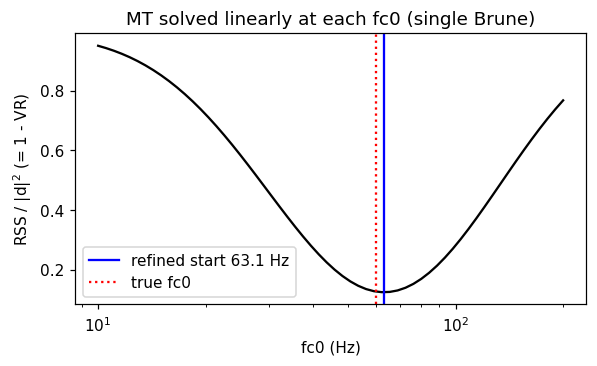

In [2]:
model = unshake.MTDCDirectivityModel()
tic = time.time()
p0 = model.find_non_linear_starting_model_params(ds)
print(f"variable projection: fc0 = {p0[6]:.2f} Hz in {time.time() - tic:.2f} s")

fc_scan = np.logspace(np.log10(10), np.log10(200), 60)
rss = []
for fc in fc_scan:
    p = model.find_non_linear_starting_model_params(ds, fc0=fc)
    rss.append(np.sum((ds.data - brune_synth(p[:6], fc)) ** 2))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.semilogx(fc_scan, np.array(rss) / np.sum(ds.data ** 2), 'k')
ax.axvline(p0[6], color='b', label=f'refined start {p0[6]:.1f} Hz')
ax.axvline(60.0, color='r', ls=':', label='true fc0')
ax.set(xlabel='fc0 (Hz)', ylabel='RSS / |d|$^2$ (= 1 - VR)', title='MT solved linearly at each fc0 (single Brune)')
ax.legend();

## 2. Monte Carlo (prior sampling)

- Samples are drawn independently from the model prior:
  - a full MT on the unit sphere, times a fixed amplitude `scale`;
  - $\log f_{c0}$ uniform over `fc0_range`;
  - $\mathbf{v}$ isotropic Gaussian ($\sigma_v$ = 900 m/s), truncated at $|\mathbf{v}| \le$ 1600 m/s.
- Each sample is weighted by a Gaussian likelihood.
- `prepare` sets `scale` from the variable-projection MT. (LSQ on the formal GFs alone ignores the STF and underestimates the amplitude about 7-fold here.)
- The noise level is taken from the starting-model residual.
- **In 10-D, almost none of the samples land near the optimum.** The effective sample size is about 1, so the MC result is only a coarse search.

monte_carlo: no noise level given, using the starting-model residual std = 3.88e-13
Note: GFs and data must be band-limited by the same filter B: gf_band=(2.0, 20.0, 200.0, 210.0), data_band=(2.0, 20.0, 200.0, 210.0)
monte_carlo: 50000 samples in 70.7 s
Result(MTDCDirectivityModel, n=50000, max VR=0.822, ESS=1.0)


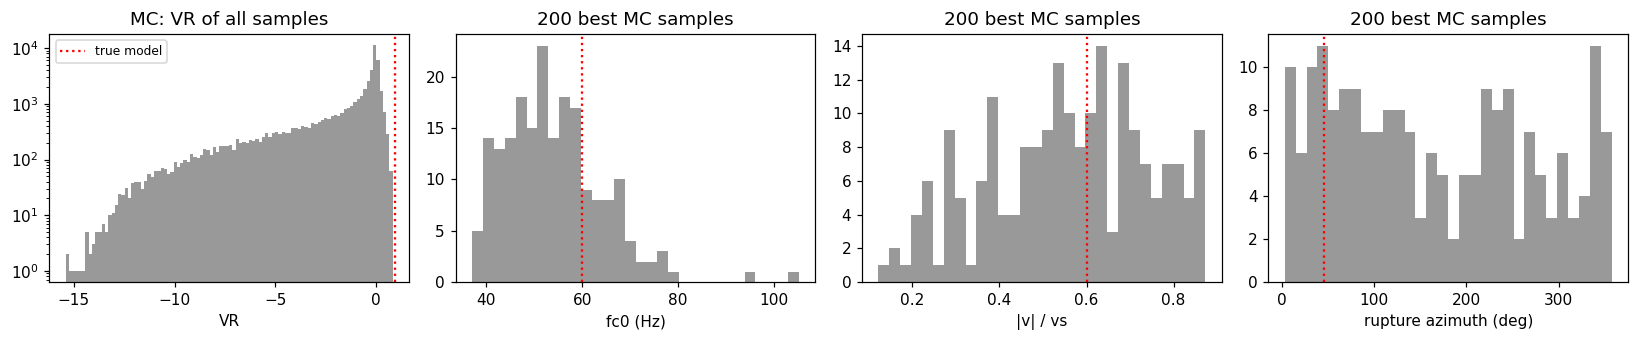

In [3]:
model_mc = unshake.MTDCDirectivityModel()
tic = time.time()
res_mc = unshake.monte_carlo(model_mc, ds, 50_000, rng=1)
t_mc = time.time() - tic
print(res_mc)
top = res_mc.top(200)
vr_mc, az_mc, pl_mc = model_mc.rupture(res_mc.params[top])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
axes[0].hist(res_mc.vr, 100, color='0.6')
axes[0].axvline(misfit.vr(ds.data, d_clean), color='r', ls=':', label='true model')
axes[0].set(xlabel='VR', title='MC: VR of all samples', yscale='log')
axes[0].legend(fontsize=8)
for ax, x, xt, lab in zip(axes[1:], (res_mc['fc0'][top], vr_mc / vs, az_mc),
                          (60.0, 0.6, 45.0), ('fc0 (Hz)', '|v| / vs', 'rupture azimuth (deg)')):
    ax.hist(x, 30, color='0.6')
    ax.axvline(xt, color='r', ls=':')
    ax.set(xlabel=lab, title='200 best MC samples')
plt.tight_layout()

## 3. Non-linear least squares

`unshake.nonlinear_least_squares(model, ds)` minimises $\tfrac12|\mathbf{r}|^2$, with:

$$\mathbf{r} = \Big[\tfrac{\sqrt{w_i}}{\sigma_i}\big(d_i - u_i(\mathbf{p})\big),\ \ \mathbf{v}/\sigma_v\Big]$$

- **Prior term.** The second term is the Gaussian prior on $\mathbf{v}$, which acts as damping. It keeps $\mathbf{v}$ determined where the data are not sensitive to it.
- **Solver.** `scipy.optimize.least_squares` (TRF) with finite bounds:
  - $|m_k| \le 3\,$`scale`;
  - $f_{c0}$ within `fc0_range`;
  - $|v_j| \le v_{max}$.
- **Conditioning.** `x_scale` puts every parameter at O(1): the MT in units of `scale`, $f_{c0}$ in units of its start value, $\mathbf{v}$ in units of $\sigma_v$.
- **Starts.** It starts from $\mathbf{p}_0$, plus 4 starts with $|\mathbf{v}| = \sigma_v/2$ in random directions.
- **Noise level.** With no noise level given, $\sigma$ is re-estimated as $\sigma^2 = \chi^2/(N - 10)$ at the optimum, and the fit is repeated once.
- **Uncertainty.** The Gauss–Newton covariance $(J^\mathsf{T}J)^{-1}$.

**Caveats:**
- **The covariance assumes white noise.** The noise here is band-limited (2–210 Hz at 1 kHz sampling), so neighbouring samples are correlated. The quoted σ are therefore too small, by roughly $\sqrt{n_t/n_{\rm eff}} \approx 1.5$.
- **$v_U$ is set by the prior alone.** All receivers lie in the horizontal plane of the source, so $\mathbf{v}\cdot\hat r_i$ does not depend on $v_U$, and $v_U = 0 \pm \sigma_v$.

In [4]:
model_ls = unshake.MTDCDirectivityModel()
tic = time.time()
p_hat, cov, info = unshake.nonlinear_least_squares(model_ls, ds, rng=1)
t_ls = time.time() - tic
sd = np.sqrt(np.diag(cov))
print('costs of the starts:', np.round(info['start_costs'], 1))
pd.DataFrame({'true': p_true, 'start (VP)': model_ls.p0, 'NLLS': p_hat, 'GN 1 sigma': sd,
              '(NLLS - true) / sigma': (p_hat - p_true) / sd}, index=names).round(4)

Note: GFs and data must be band-limited by the same filter B: gf_band=(2.0, 20.0, 200.0, 210.0), data_band=(2.0, 20.0, 200.0, 210.0)
nonlinear_least_squares: 5 start(s), 32 forward evaluations in 0.8 s; cost 7496, VR 0.9272, sigma 2.97e-13 (estimated)
costs of the starts: [4391.1 4391.1 4391.1 4391.1 4391.1]


,true,start (VP),NLLS,GN 1 sigma,(NLLS - true) / sigma
Mnn,-0.0055,-0.0119,-0.0041,0.0081,0.1715
Mee,0.9461,0.9012,0.9439,0.0087,-0.2507
Mdd,-0.3406,-0.3634,-0.3642,0.0102,-2.3042
Mne,-0.1096,-0.1051,-0.1095,0.0014,0.0745
Mnd,-0.2679,-0.2616,-0.2717,0.0017,-2.2064
Med,0.2016,0.1896,0.2015,0.0017,-0.0531
fc0,60.0000,63.1267,59.9739,0.1551,-0.1683
v_e,772.1606,0.0000,745.1837,9.6944,-2.7827
v_n,772.1606,0.0000,762.9151,9.8305,-0.9405
v_u,-0.0000,0.0000,0.0000,900.0000,0.0000


In [5]:
# Rupture speed, azimuth and plunge, and lune position: draws from N(p_hat, cov) (no forward modelling)
draws = np.random.default_rng(2).multivariate_normal(p_hat, cov, 5000)
vr_d, az_d, pl_d = model_ls.rupture(draws)
vr_t, az_t, _ = (x[0] for x in model_ls.rupture(p_true))
g_d, de_d = np.degrees(mt.lune(draws[:, :6]))
g_t, de_t = np.degrees(mt.lune(m_true))
c_dc_d = mt.decompose(draws[:, :6])[2]
rows = {'|v| / vs (horizontal)': (np.hypot(draws[:, 7], draws[:, 8]) / vs, 0.6),
        'rupture azimuth (deg)': (az_d, az_t),
        'fc0 (Hz)': (draws[:, 6], 60.0),
        'lune gamma (deg)': (g_d, g_t), 'lune delta (deg)': (de_d, de_t),
        'DC fraction': (c_dc_d, c_dc)}
pd.DataFrame({k: {'true': t, 'median': np.median(x), '2.5 %': np.percentile(x, 2.5),
                  '97.5 %': np.percentile(x, 97.5)} for k, (x, t) in rows.items()}).T.round(3)

,true,median,2.5 %,97.5 %
|v| / vs (horizontal),0.600,0.586,0.574,0.597
rupture azimuth (deg),45.000,44.324,43.419,45.249
fc0 (Hz),60.000,59.971,59.667,60.285
lune gamma (deg),-6.587,-6.007,-6.288,-5.730
lune delta (deg),17.975,17.069,15.683,18.458
DC fraction,0.600,0.623,0.608,0.637


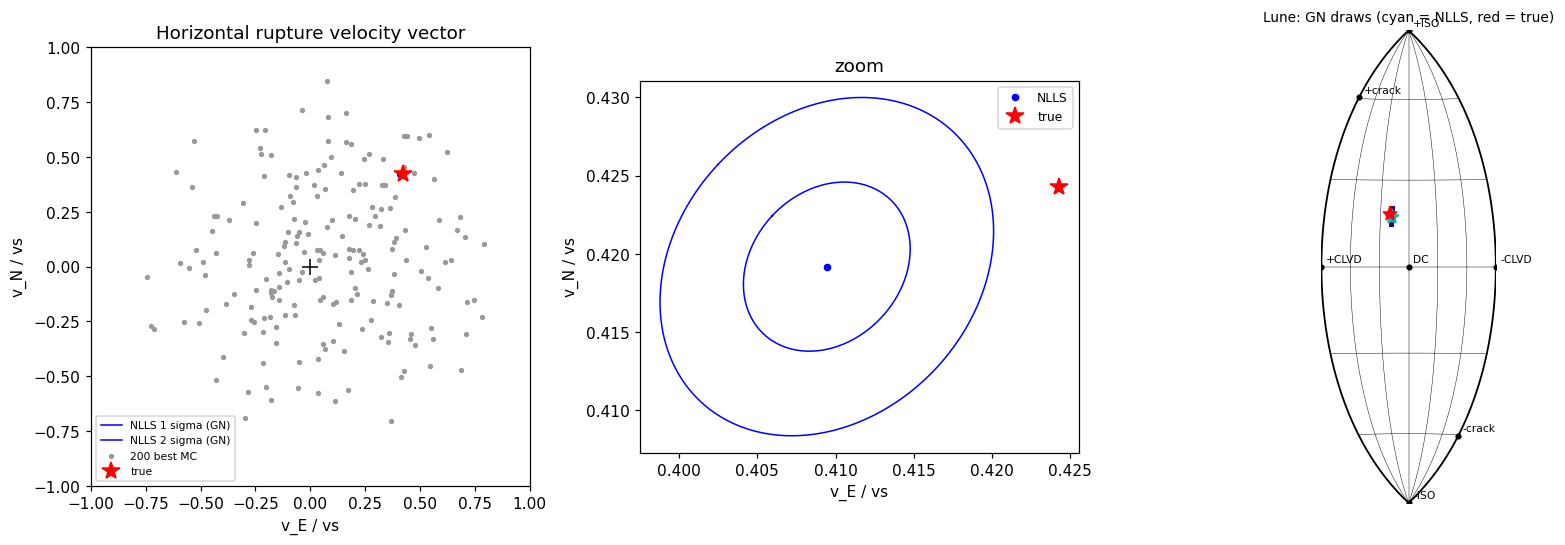

In [6]:
fig = plt.figure(figsize=(15, 5))
# (v_E, v_N): GN 1 and 2 sigma ellipses, best MC samples, truth
ax = fig.add_subplot(1, 3, 1)
C = cov[7:9, 7:9]
w_e, V_e = np.linalg.eigh(C)
th = np.linspace(0, 2 * np.pi, 200)
for k in (1, 2):
    ell = p_hat[7:9, None] + k * V_e @ (np.sqrt(w_e)[:, None] * np.vstack([np.cos(th), np.sin(th)]))
    ax.plot(ell[0] / vs, ell[1] / vs, 'b', lw=1, label=f'NLLS {k} sigma (GN)')
ax.scatter(res_mc.params[top, 7] / vs, res_mc.params[top, 8] / vs, s=6, c='0.6', label='200 best MC')
ax.plot(*(v_true[:2] / vs), 'r*', ms=12, label='true')
ax.plot(0, 0, 'k+', ms=10)
ax.set(xlabel='v_E / vs', ylabel='v_N / vs', aspect='equal', xlim=(-1, 1), ylim=(-1, 1),
       title='Horizontal rupture velocity vector')
ax.legend(fontsize=7, loc='lower left')
# zoom
ax = fig.add_subplot(1, 3, 2)
for k in (1, 2):
    ell = p_hat[7:9, None] + k * V_e @ (np.sqrt(w_e)[:, None] * np.vstack([np.cos(th), np.sin(th)]))
    ax.plot(ell[0] / vs, ell[1] / vs, 'b', lw=1)
ax.plot(*(p_hat[7:9] / vs), 'b.', ms=8, label='NLLS')
ax.plot(*(v_true[:2] / vs), 'r*', ms=12, label='true')
ax.set(xlabel='v_E / vs', ylabel='v_N / vs', aspect='equal', title='zoom')
ax.legend(fontsize=8)
# lune: GN draws, NLLS, truth
ax = fig.add_subplot(1, 3, 3)
plot.lune(m6=draws[:, :6], ax=ax, bins=(60, 120))
ax.plot(*plot._hammer(*mt.lune(p_hat[:6])), 'c*', ms=10)
ax.plot(*plot._hammer(*np.radians([g_t, de_t])), 'r*', ms=10)
ax.set_title('Lune: GN draws (cyan = NLLS, red = true)', fontsize=9)
plt.tight_layout()

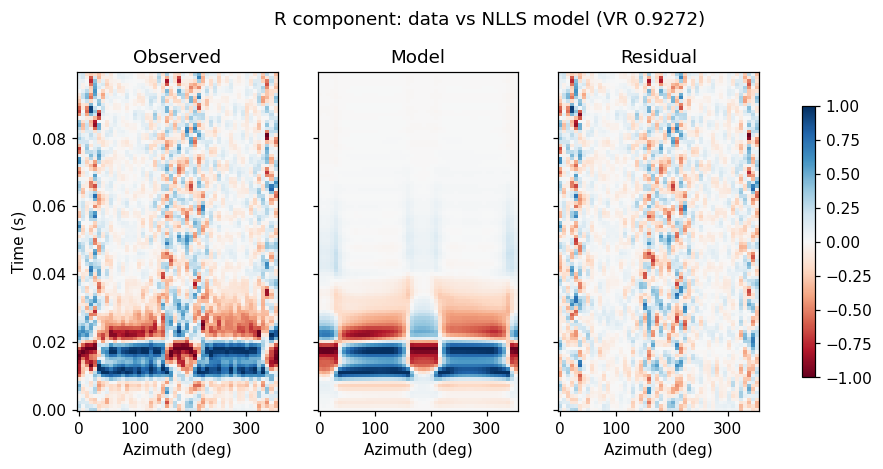

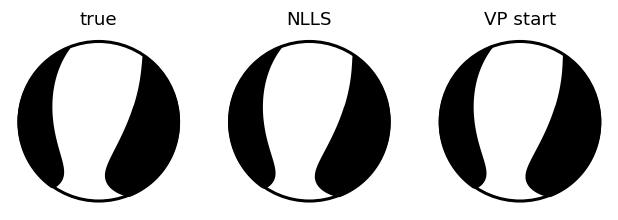

In [7]:
synth_ls = model_ls.forward(p_hat, ds)[0]
fig = plot.wavefield(comp(ds, 'R'), comp(make_ds(synth_ls), 'R').data, x=rec_az, xlabel='Azimuth (deg)')
fig.suptitle(f'R component: data vs NLLS model (VR {info["vr"]:.4f})', y=1.02)
fig, axes = plt.subplots(1, 3, figsize=(7, 2.5))
for ax, (lab, m6) in zip(axes, (('true', m_true), ('NLLS', p_hat[:6]), ('VP start', model_ls.p0[:6]))):
    plot.beachball(m6, ax=ax)
    ax.set_title(lab)

## 4. Checks: noise-free data, and a source with no DC part
- **Noise-free data.** NLLS should recover the true parameters almost exactly.
- **Pure tensile crack** (eigenvalues 3:1:1, $C_{DC} = 0$). The true source has no DC part, so the true $\mathbf{v}$ has no effect on the data.
  - The noise lets the estimated MT pick up a small spurious DC part (below 1 %). That gives $\mathbf{v}$ a weak, noise-driven sensitivity.
  - Expect a $\mathbf{v}$ that is not significant (within about 2σ of 0) and loosely constrained (σ a sizeable fraction of the prior $\sigma_v$).
  - With $C_{DC} \approx 0$, the recovered $\mathbf{v}$ should not be interpreted.

In [8]:
p_nf, cov_nf, _ = unshake.nonlinear_least_squares(unshake.MTDCDirectivityModel(), make_ds(d_clean), rng=1)
print('noise-free: max |NLLS - true| / |true|: MT', np.abs(p_nf[:6] - m_true).max() / mt.norm(m_true),
      ' fc0', abs(p_nf[6] - 60) / 60, ' v', np.linalg.norm(p_nf[7:] - v_true) / np.linalg.norm(v_true))

m_crack = mt.from_33(V_axes @ np.diag([3.0, 1.0, 1.0]) @ V_axes.T) / 3.0
p_crack = np.r_[m_crack, 60.0, v_true]
d_crack = add_noise(unshake.MTDCDirectivityModel(scale=1.0).forward(p_crack, ds_gf)[0], np.random.default_rng(3))
p_c, cov_c, _ = unshake.nonlinear_least_squares(unshake.MTDCDirectivityModel(), make_ds(d_crack), rng=1)
print(f"crack: DC fraction of the estimate {mt.decompose(p_c[:6])[2]:.3f}; fc0 {p_c[6]:.2f} Hz; "
      f"v = {np.round(p_c[7:])} +/- {np.round(np.sqrt(np.diag(cov_c))[7:])} m/s (prior sigma_v = 900)")

Note: GFs and data must be band-limited by the same filter B: gf_band=(2.0, 20.0, 200.0, 210.0), data_band=(2.0, 20.0, 200.0, 210.0)
nonlinear_least_squares: 5 start(s), 38 forward evaluations in 0.9 s; cost 0.7361, VR 1.0000, sigma 2.54e-17 (estimated)
noise-free: max |NLLS - true| / |true|: MT 1.9341171573936884e-13  fc0 1.1344999014302933e-13  v 1.0767279333677746e-12
Note: GFs and data must be band-limited by the same filter B: gf_band=(2.0, 20.0, 200.0, 210.0), data_band=(2.0, 20.0, 200.0, 210.0)
nonlinear_least_squares: 5 start(s), 50 forward evaluations in 1.2 s; cost 7496, VR 0.9494, sigma 1.41e-13 (estimated)
crack: DC fraction of the estimate 0.006; fc0 60.19 Hz; v = [-677.  834.    0.] +/- [433. 463. 900.] m/s (prior sigma_v = 900)


## 5. Comparison

In [9]:
def summary(p):
    vr_, az_, _ = (x[0] for x in model_ls.rupture(p))
    return p[6], vr_ / vs, az_, float(misfit.vr(ds.data, model_ls.forward(p, ds)[0]))
rows = {'true': summary(p_true), 'VP start (v = 0)': summary(model_ls.p0),
        'MC best of 50k': summary(res_mc.best), 'NLLS': summary(p_hat)}
tab = pd.DataFrame(rows, index=['fc0 (Hz)', '|v| / vs', 'azimuth (deg)', 'VR']).T
tab['time (s)'] = [np.nan, np.nan, t_mc, t_ls]
tab['forward evals'] = [np.nan, np.nan, 50_000, info['nfev']]
tab.round(3)

,fc0 (Hz),|v| / vs,azimuth (deg),VR,time (s),forward evals
true,60.000,0.600,45.000,0.927,NaN,NaN
VP start (v = 0),63.127,0.000,0.000,0.876,NaN,NaN
MC best of 50k,70.694,0.433,235.399,0.822,70.902,50000.0
NLLS,59.974,0.586,44.326,0.927,1.027,32.0


**Summary:**
- **Variable projection** gives a good starting $f_{c0}$ and MT cheaply. With directivity in the data its $f_{c0}$ is biased by a few Hz, because one Brune has to fit both the forward and backward directions.
- **Plain prior-sampling MC is a poor tool in 10-D.** Even 50k samples (about 40 s) leave an ESS of about 1, and the best sample is far from the optimum.
- **NLLS converges in under a second**, a few tens of forward evaluations per start, and recovers the MT, $f_{c0}$ and the horizontal $\mathbf{v}$. The multi-starts all reach the same minimum here.
- **The GN covariance is a quick local uncertainty** and is optimistic for correlated noise.
- **For sources with little DC**, $\mathbf{v}$ is weakly and noisily constrained (section 4). Report it together with $C_{DC}$.

**Next step (planned):** an adaptive Metropolis MCMC started from the NLLS optimum and its covariance, for a full posterior. HMC/NUTS (NumPyro, PyMC) is a possible later improvement and would need a differentiable forward model.